# Lo que cuesta el dispositivo: cuantización, diafonía y apertura del píxel en un arreglo de 8 x 8

**Pregunta:** ¿Cuánto cuestan la cuantización de la fase, la diafonía entre píxeles y la apertura del píxel a un holograma de un arreglo de 8 x 8 trampas, en luz y en uniformidad?

- Nivel: 1, fundamentos.
- Requisitos previos: `01-fourier-optics/01-where-the-light-goes`, que presenta la envolvente del píxel.
- Tiempo de lectura: unos 15 minutos. El notebook se ejecuta en cerca de 20 segundos.

## Objetivos

Un holograma se calcula en una pantalla ideal y se muestra en una real. La pantalla ideal muestra cualquier fase con exactitud, tiene píxeles puntuales y deja que cada píxel actúe solo. Un modulador espacial de luz real redondea la fase a unos pocos cientos de niveles en el mejor caso, cubre solo parte de cada píxel, deja que los píxeles vecinos se filtren entre sí y fluctúa en el tiempo. Cada uno de estos defectos tiene un número, y el notebook los mide de a uno sobre el mismo holograma. Al terminar puedes:

- nombrar los cuatro efectos del modelo del dispositivo y decir qué le hace cada uno a un arreglo de trampas;
- predecir la luz que se pierde por cuantización a partir del número de niveles, y decir dónde deja de funcionar la predicción;
- sumar los efectos uno a uno y leer cuál domina.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.core import score as scoring
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.device import Device, pixel_envelope
from pipeline.model.holo.core.forward import trap_bins
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee el caso C08 de `data/examples/cases.json`: un arreglo de 8 x 8 en un SLM de 128 x 128 píxeles, con los parámetros de dispositivo del caso.

- Propietario: este repositorio; el caso es sintético, y sus parámetros de diafonía son los ajustados por Schroff et al. (2023).
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C08.

In [2]:
# caso C08: un arreglo de 8 x 8 en un dispositivo con fase de 4 bits, diafonía, factor de llenado de 0.85 y
# parpadeo
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C08"]
setup = build.setup_of(rec)
target = build.target_of(rec)
device_c08 = build.device_of(rec)
print(rec["case_id"], "|", len(target.traps), "trampas | SLM", setup.n_pix, "x", setup.n_pix, "píxeles")
print(device_c08)

C08_device_limited | 64 trampas | SLM 128 x 128 píxeles
Device(bit_depth=4, crosstalk=(1.24, 1.8), upsample=3, fill_factor=0.85, flicker_rad=0.05, lut_gamma=1.0)


## Método

### Paso 1: un holograma calculado para la pantalla ideal

El modelo de dispositivo del pipeline convierte un patrón de fase ideal en lo que muestra un modulador real, en este orden: la fase se envuelve, se redondea a $N = 2^b$ niveles equiespaciados, pasa por la respuesta del cristal líquido (una recta en este caso) y se perturba con un parpadeo aleatorio de un rms dado. El patrón mostrado se sobremuestrea a 3 x 3 muestras por píxel, se difumina con el núcleo de diafonía $K = \mathcal{F}^{-1}\{\exp[-(|k_x|^q + |k_y|^q)/\sigma^q]\}$ con $\sigma = 1{,}24$ y $q = 1{,}80$ (Schroff et al., 2023, Métodos), se transforma y se multiplica por la envolvente de la apertura del píxel, $\mathrm{sinc}(a x / \lambda f)\,\mathrm{sinc}(a y / \lambda f)$ con $a = \sqrt{\text{fill}}\,p$. La primera celda calcula el holograma que muestran todos los pasos siguientes: Gerchberg-Saxton ponderado (M06) durante 30 iteraciones sobre el modelo ideal.

In [3]:
# el holograma del que parten los pasos siguientes: GS ponderado sobre el modelo ideal, 30 iteraciones
res_gsw = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
ideal = res_gsw.history[-1]
print(f"modelo ideal: eficiencia {ideal['efficiency']:.4f}  "
      f"uniformidad {ideal['uniformity']:.4f}  desv. rel. {ideal['rel_std']:.2f} %")

modelo ideal: eficiencia 0.8014  uniformidad 0.9935  desv. rel. 0.33 %


### Paso 2: la apertura del píxel, antes de redondear nada

El dispositivo más barato del modelo, `Device()`, tiene píxeles cuadrados que llenan el paso, sin cuantización, sin diafonía y sin parpadeo. Ni siquiera este dispositivo es la pantalla ideal: un píxel de ancho finito difracta menos luz hacia el borde del campo, de modo que las trampas lejos del eje reciben menos. La celda lee la envolvente en las 64 posiciones de las trampas y evalúa el mismo holograma a través de ese dispositivo con el evaluador del pipeline, la única definición con la que se juzga a todos los métodos.

In [4]:
# la apertura del píxel sola: un dispositivo con factor de llenado 1, sin cuantización, sin diafonía, sin
# parpadeo
aperture = Device()
iy, ix = trap_bins(setup, target.traps)
at_traps = pixel_envelope(setup, aperture)[iy, ix]
print(f"envolvente sobre las 64 trampas, mínimo y máximo: {at_traps.min():.4f} {at_traps.max():.4f}")
shown = scoring.score(rec, res_gsw.phi, setup=setup, device=aperture)
print(f"solo la apertura: eficiencia {shown['efficiency']:.4f}  "
      f"uniformidad {shown['uniformity']:.4f}  desv. rel. {shown['rel_std_pct']:.2f} %")

envolvente sobre las 64 trampas, mínimo y máximo: 0.8836 0.9975
solo la apertura: eficiencia 0.7534  uniformidad 0.9116  desv. rel. 4.08 %


La apertura sola ya cuesta luz y uniformidad: la envolvente varía cerca de 11 por ciento entre las 64 trampas, de 0,8836 a 0,9975, y la eficiencia baja de 0,8014 a 0,7534 mientras la desviación estándar relativa sube de 0,33 a 4,08 por ciento. Todo lo que agreguen las celdas siguientes se suma sobre este piso.

### Paso 3: cuantización

Redondear la fase a $N$ niveles deja un error aproximadamente uniforme en $\pm \pi / N$. La media de $e^{i\epsilon}$ para ese error es $\mathrm{sinc}(1/N) = \sin(\pi/N)/(\pi/N)$, de modo que la luz que se queda en fase con el campo ideal, y llega a las trampas, baja en $\mathrm{sinc}^2(1/N)$. Esa es la eficiencia de primer orden de una red de fase escalonada, y la ficha del modelo del dispositivo la da como eficiencia de cuantización. La celda muestra el mismo holograma con 8, 6, 4, 3, 2 y 1 bits, y compara la eficiencia medida, relativa a 8 bits, con la estimación.

In [5]:
# el mismo holograma mostrado con 8, 6, 4, 3, 2 y 1 bits de fase (la apertura del píxel se mantiene)
bits = (8, 6, 4, 3, 2, 1)
quant = {b: scoring.score(rec, res_gsw.phi, setup=setup, device=Device(bit_depth=b)) for b in bits}
for b, s in quant.items():
    ratio = s["efficiency"] / quant[8]["efficiency"]
    print(f"{b} bits: razón de eficiencia a 8 bits {ratio:.4f} "
          f"(sinc^2(1/N) {np.sinc(1 / 2**b) ** 2:.4f})  desv. rel. {s['rel_std_pct']:.2f} %")

8 bits: razón de eficiencia a 8 bits 1.0000 (sinc^2(1/N) 0.9999)  desv. rel. 4.09 %
6 bits: razón de eficiencia a 8 bits 0.9992 (sinc^2(1/N) 0.9992)  desv. rel. 4.18 %
4 bits: razón de eficiencia a 8 bits 0.9877 (sinc^2(1/N) 0.9872)  desv. rel. 4.73 %
3 bits: razón de eficiencia a 8 bits 0.9527 (sinc^2(1/N) 0.9496)  desv. rel. 8.58 %
2 bits: razón de eficiencia a 8 bits 0.8226 (sinc^2(1/N) 0.8106)  desv. rel. 21.17 %
1 bits: razón de eficiencia a 8 bits 0.8108 (sinc^2(1/N) 0.4053)  desv. rel. 75.23 %


La figura grafica a la izquierda la razón de eficiencia medida frente a la estimación, y a la derecha la desviación estándar relativa de las trampas.

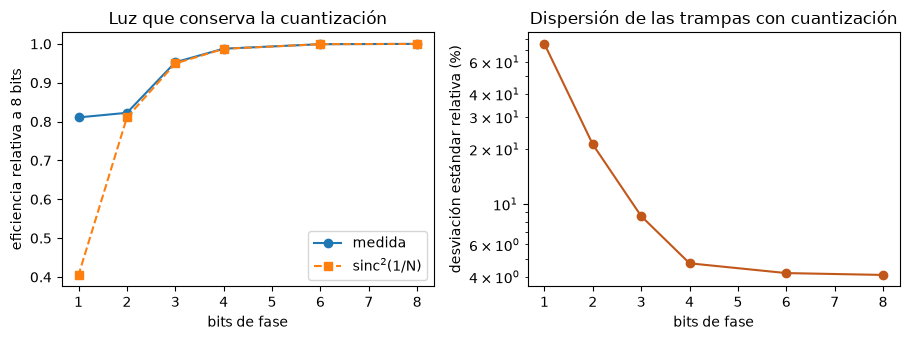

In [6]:
# razón de eficiencia frente a la estimación sinc^2, y la dispersión, al perder bits de fase
fig, (a, b) = plt.subplots(1, 2, figsize=(9.2, 3.5))
a.plot(bits, [quant[k]["efficiency"] / quant[8]["efficiency"] for k in bits], "o-", label="medida")
a.plot(bits, [np.sinc(1 / 2**k) ** 2 for k in bits], "s--", label="sinc$^2$(1/N)")
a.set_xlabel("bits de fase")
a.set_ylabel("eficiencia relativa a 8 bits")
a.set_title("Luz que conserva la cuantización")
a.legend()
b.semilogy(bits, [quant[k]["rel_std_pct"] for k in bits], "o-", color="#c2571a")
b.set_xlabel("bits de fase")
b.set_ylabel("desviación estándar relativa (%)")
b.set_title("Dispersión de las trampas con cuantización")
plt.tight_layout()
plt.show()

La estimación es precisa donde la cuantización es leve: con 4 bits la razón medida es 0,9877 frente a 0,9872, con 3 bits 0,9527 frente a 0,9496, e incluso con 2 bits 0,8226 frente a 0,8106. Cuatro bits pierden solo cerca de 1 por ciento de la luz, así que la eficiencia no es lo que hace importante a la cuantización. La dispersión sí lo es: la desviación estándar relativa sube de 4,09 por ciento con 8 bits a 4,73 con 4 bits y 8,58 con 3, y luego salta a 21,17 con 2 bits y 75,23 con 1 bit, donde las trampas ya no son iguales en absoluto. El punto de 1 bit es también donde falla la estimación, 0,8108 medido frente a 0,4053 estimado. Un patrón de fase binario no es una perturbación pequeña de uno ideal, porque escribe además una imagen especular del arreglo, y la estimación sinc describe solo la luz que se queda con el campo deseado. La causa del desajuste con 1 bit no se probó aquí. La figura muestra un holograma en un arreglo; no muestra cómo cambiaría la pérdida con otra geometría de trampas.

### Paso 4: todos los efectos, sumados de a uno

El dispositivo del caso C08 tiene cuatro efectos juntos: 4 bits, diafonía, un factor de llenado de 0,85 y un parpadeo de 0,05 rad. La celda construye el dispositivo en ese orden, desde la apertura sola hasta el dispositivo completo del caso, y evalúa el mismo holograma en cada etapa. Como el parpadeo es aleatorio, el evaluador del pipeline lo sortea de un flujo con semilla ligado al caso, de modo que cada corrida ve el mismo parpadeo.

In [7]:
# los efectos sumados uno a uno: apertura, 4 bits, diafonía, factor de llenado 0.85, parpadeo (el
# dispositivo del caso)
stages = {
    "apertura": Device(),
    "+ 4 bits": Device(bit_depth=4),
    "+ diafonía": Device(bit_depth=4, crosstalk=(1.24, 1.8), upsample=3),
    "+ llenado 0.85": Device(bit_depth=4, crosstalk=(1.24, 1.8), upsample=3, fill_factor=0.85),
    "+ parpadeo": device_c08,
}
stack = {k: scoring.score(rec, res_gsw.phi, setup=setup, device=d) for k, d in stages.items()}
for k, s in stack.items():
    print(f"{k:22s} eficiencia {s['efficiency']:.4f}  uniformidad {s['uniformity']:.4f}  "
          f"desv. rel. {s['rel_std_pct']:.2f} %")

apertura               eficiencia 0.7534  uniformidad 0.9116  desv. rel. 4.08 %
+ 4 bits               eficiencia 0.7441  uniformidad 0.8920  desv. rel. 4.73 %
+ diafonía             eficiencia 0.6923  uniformidad 0.7429  desv. rel. 12.69 %
+ llenado 0.85         eficiencia 0.6977  uniformidad 0.7465  desv. rel. 12.52 %
+ parpadeo             eficiencia 0.6838  uniformidad 0.7457  desv. rel. 13.07 %


Las barras dan la desviación estándar relativa tras cada efecto añadido, con la línea discontinua en el valor del modelo ideal.

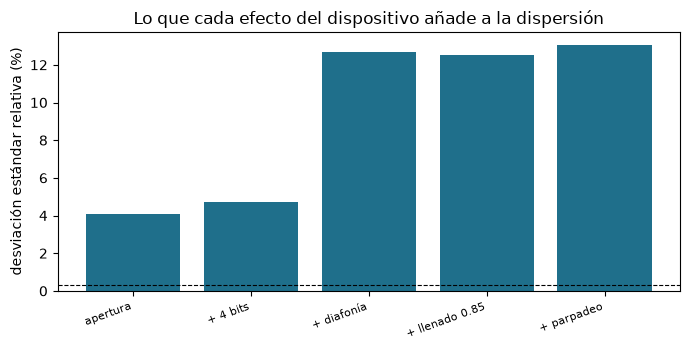

In [8]:
# desviación estándar relativa de las trampas tras cada efecto añadido
fig, ax = plt.subplots(figsize=(7.0, 3.6))
ax.bar(range(len(stack)), [s["rel_std_pct"] for s in stack.values()], color="#1f6f8b")
ax.set_xticks(range(len(stack)))
ax.set_xticklabels(list(stack), rotation=20, ha="right", fontsize=8)
ax.axhline(ideal["rel_std"], color="k", linewidth=0.8, linestyle="--")
ax.set_ylabel("desviación estándar relativa (%)")
ax.set_title("Lo que cada efecto del dispositivo añade a la dispersión")
plt.tight_layout()
plt.show()

La diafonía domina. Pasar de 4 bits a 4 bits más diafonía sube la dispersión de 4,73 a 12,69 por ciento y baja la eficiencia de 0,7441 a 0,6923, una pérdida de 0,0518 de la luz, mayor que toda la pérdida por cuantización. Una razón probable es el núcleo: con $\sigma = 1{,}24$ por píxel la fase de un píxel se reparte entre sus vecinos, lo que filtra pasa-bajos el holograma, y el detalle de alta frecuencia que dirige la luz a las trampas exteriores es lo que se pierde. Las dos etapas siguientes son pequeñas. El factor de llenado de 0,85 baja un poco la dispersión, a 12,52 por ciento, y sube un poco la eficiencia, a 0,6977: en el modelo del pipeline un píxel más pequeño aplana la envolvente y la potencia perdida en el área muerta no se cobra, como declara el módulo del dispositivo, así que esta etapa no debe leerse como un beneficio de un dispositivo real. El parpadeo añade cerca de medio punto de dispersión, 13,07 por ciento, con una eficiencia de 0,6838, a partir de un sorteo con semilla. La pila termina con la eficiencia en 85 por ciento de la ideal (0,6838 frente a 0,8014) y la dispersión unas 40 veces mayor. La figura no separa la apertura de los demás una vez que interactúan; el orden de las adiciones cambia cada paso pero no el punto final.

## Resultados

**Respuesta:** El dispositivo le cuesta al arreglo de 8 x 8 cerca de 15 por ciento de su luz y la mayor parte de su uniformidad, y la diafonía es el efecto que importa. A través del dispositivo completo del caso C08 el holograma que tiene 0,8014 de eficiencia y una desviación estándar relativa de 0,33 por ciento en la pantalla ideal muestra 0,6838 y 13,07 por ciento. La cuantización sola es leve: 4 bits conservan 0,9877 de la luz, como predice la estimación $\mathrm{sinc}^2(1/N)$ de 0,9872, y suben la dispersión de 4,09 a 4,73 por ciento; la apertura del píxel sola ya baja la eficiencia de 0,8014 a 0,7534. La diafonía sube la dispersión de 4,73 a 12,69 por ciento.

Lo que el notebook no muestra es lo que puede recuperar un método que conoce el dispositivo, que mide el notebook de nivel 3 `06-device-and-aberrations/03-crosstalk-aware-cg-against-cg`, ni cómo depende la pérdida de la geometría del arreglo.

## Resumen

- El modelo del dispositivo tiene cuatro efectos: cuantización, diafonía, apertura del píxel y parpadeo, aplicados a la fase antes de calcular la luz.
- La apertura sola baja la eficiencia de este arreglo de 0,8014 a 0,7534 y fija un piso de 4,08 por ciento en la dispersión.
- La cuantización cuesta luz como $\mathrm{sinc}^2(1/N)$ hasta 2 bits y uniformidad desde 4 bits hacia abajo (4,09 a 4,73 por ciento con 4 bits, 21,17 con 2); la estimación falla para un patrón binario.
- La diafonía es el efecto dominante: añade más dispersión que la cuantización, el factor de llenado y el parpadeo juntos.

## Referencias

- Schroff et al. (2023). Accurate holographic light potentials using pixel crosstalk modelling. Scientific Reports 13, 3252. https://doi.org/10.1038/s41598-023-30296-6
- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913